<a href="https://colab.research.google.com/github/vaishnavisachinyadav-ui/lunaai/blob/main/ML_Activity1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Features:", housing.feature_names)
print("Target  :", housing.target_names)


Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target  : ['MedHouseVal']


In [4]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:", list(df.columns))
print("\nData types:")
print(df.dtypes)

Rows   : 20640
Columns: 9
Column names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate records:", df.duplicated().sum())

# Handle missing values and duplicates
rows_before = len(df)
df = df.dropna()
df = df.drop_duplicates()
print("\nRows before:", rows_before, "| Rows after:", len(df))

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate records: 0

Rows before: 20640 | Rows after: 20640


In [8]:
X = df[['MedInc']]
y = df['MedHouseVal']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Correlation:", round(df['MedInc'].corr(df['MedHouseVal']), 3))

X shape: (20640, 1)
y shape: (20640,)
Correlation: 0.688


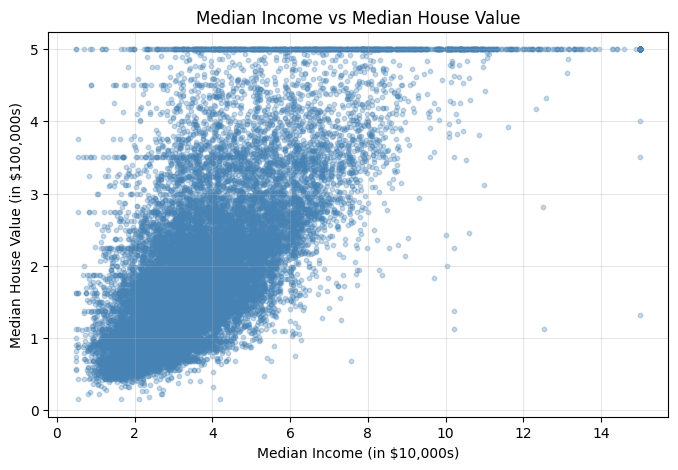

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.3, color='steelblue', s=10)
plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (in $10,000s)")
plt.ylabel("Median House Value (in $100,000s)")
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records :", len(X_test))

Training records: 16512
Testing records : 4128


In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficient = model.coef_[0]
intercept = model.intercept_

print("Coefficient:", round(coefficient, 4))
print("Intercept  :", round(intercept, 4))
print(f"\nMedHouseVal = {coefficient:.4f} x MedInc + {intercept:.4f}")

Coefficient: 0.4193
Intercept  : 0.4446

MedHouseVal = 0.4193 x MedInc + 0.4446


In [12]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Median Income': X_test['MedInc'].values,
    'Actual Value': y_test.values,
    'Predicted Value': y_pred
})
results['Difference'] = results['Actual Value'] - results['Predicted Value']
results.head(10).round(3)

,Median Income,Actual Value,Predicted Value,Difference
0,1.681,0.477,1.150,-0.673
1,2.531,0.458,1.506,-1.048
2,3.480,5.000,1.904,3.096
3,5.738,2.186,2.851,-0.665
4,3.725,2.780,2.007,0.773
5,4.715,1.587,2.422,-0.835
6,5.084,1.982,2.576,-0.594
7,3.691,1.575,1.992,-0.417
8,4.804,3.400,2.459,0.941
9,8.113,4.466,3.847,0.619


In [13]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

MAE  : 0.6299
MSE  : 0.7091
RMSE : 0.8421
R2   : 0.4589


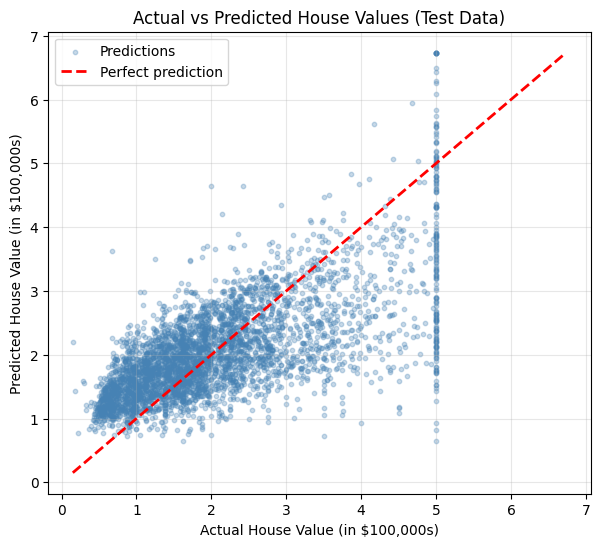

In [14]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='steelblue', s=10, label='Predictions')

low  = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], color='red', linestyle='--', linewidth=2, label='Perfect prediction')

plt.title("Actual vs Predicted House Values (Test Data)")
plt.xlabel("Actual House Value (in $100,000s)")
plt.ylabel("Predicted House Value (in $100,000s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
print("Training MedInc range:", X_train['MedInc'].min(), "to", X_train['MedInc'].max())

new_income = 5.0   # = $50,000 (must be within the range above)

predicted_value = model.predict(pd.DataFrame({'MedInc': [new_income]}))[0]

print(f"\nNew Median Income    : {new_income} (= ${new_income * 10000:,.0f})")
print(f"Predicted House Value: ${predicted_value * 100000:,.2f}")

Training MedInc range: 0.4999 to 15.0001

New Median Income    : 5.0 (= $50,000)
Predicted House Value: $254,128.98
